In [1]:
%reload_ext eradiate.tutorials

*Last updated: 2026-08-23 14:37 (eradiate v1.2.0)*

## Helper functions and imports

We start as for all tutorials with some imports and helper functions

In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
import eradiate

eradiate.set_mode("mono")

In [4]:
from eradiate.experiments import AtmosphereExperiment
from eradiate.grid import PlaneParallelGridCoords
from eradiate.radprops import ParticleProperties
from eradiate.scenes.atmosphere import (
    HeterogeneousAtmosphere,
    MolecularAtmosphere,
    ParticleField,
    ParticleProfile,
)
from eradiate.scenes.geometry import PlaneParallelGeometry
from eradiate.scenes.illumination import DirectionalIllumination
from eradiate.scenes.measure import PerspectiveCameraMeasure
from eradiate.units import to_quantity
from eradiate.units import unit_registry as ureg

In [5]:
def plot_camera(res, vmax=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1)
    res.squeeze(drop=True).plot.imshow(
        ax=ax,
        origin="upper",
        cmap="Blues_r",
        robust=True,
        add_colorbar=True,
        vmin=0,
        vmax=vmax,
    )
    ax.set_aspect(1)

## Particle properties

A `ParticleField` needs a table of particle radiative properties (extinction, single-scattering albedo, phase function) as a function of wavelength and of effective radius $r_{eff}$ and effective variance $v_{eff}$. This is the *Prt v1* dataset format. Here we use a water cloud droplet dataset (25 values of $r_{eff}$ at 670 nm) from the IPRT model intercomparison project, Case C3 "Cumulus cloud". This test dataset is part of the Eradiate registry:

In [6]:
properties = eradiate.fresolver.load_dataset(
    "tutorials/particle_field/watercloud_670-prt_v1.nc"
)
particle_properties = ParticleProperties(properties)
particle_properties.reff

Magnitude,[1.0 2.0 3.0 4.0 5.0 6.0 7.0 8.0 9.0 10.0 11.0 12.0 13.0 14.0 15.0 16.0 17.0 18.0 19.0 20.0 21.0 22.0 23.0 24.0 25.0]
Units,micrometer


## Particle profile

The spatial distribution of particles is defined by a *Ppr v1* dataset: a sparse list of populated voxels on a 3D grid, each with a mass concentration and a $(r_{eff}, v_{eff})$ pair. Here we use one time step of a "UCLA-LES large-eddy simulation of shallow cumulus convection", thresholded on liquid water content to keep only cloudy voxels.

In [7]:
profile_data = eradiate.fresolver.load_dataset(
    "tutorials/particle_field/shallow_convection-ppr_v1.nc"
)
profile = ParticleProfile(data=profile_data)
print(f"{profile_data.sizes['index']} cloudy voxels")

214925 cloudy voxels


## Grid and geometry

The render grid must be regular on all three axes, so we resample the profile's (irregular) vertical levels to a regular grid at its finest native resolution.

The LES's lowest thermodynamic level sits *below* the surface (it's a standard sub-surface reference level used by the model's vertical scheme at the ground boundary). We clip it to 0, which the molecular atmosphere we add below also requires.

In [8]:
def regular_z_levels(profile):
    z = to_quantity(profile.data["z_levels"])
    z0 = max(z[0], 0 * z.units)
    min_gap = np.diff(z).min()
    n = int(round((z[-1] - z0) / min_gap)) * 2 + 1
    return np.linspace(z0, z[-1], n)


grid = PlaneParallelGridCoords(
    edges_x=to_quantity(profile.data["x_levels"]),
    edges_y=to_quantity(profile.data["y_levels"]),
    levels=regular_z_levels(profile),
).centered()

geometry = PlaneParallelGeometry(
    grid=grid, toa_altitude=grid.levels[-1], ground_altitude=grid.levels[0]
)
geometry

PlaneParallelGeometry(toa_altitude=5504.02001953125 m, ground_altitude=0.0 m, grid=PlaneParallelGridCoords(
  x: [-3200.0 m, 3200.0 m], 256 cells
  y: [-3200.0 m, 3200.0 m], 256 cells
  z: [0.0 m, 5504.02001953125 m], 440 layers
), filter_type=<FilterType.NEAREST: 1>, wrap_mode=<WrapMode.CLAMP: 0>, width=1000000.0 km)

## Assembling the particle field

We now combine the profile, the properties and the geometry into a `ParticleField`

In [9]:
field = ParticleField(
    profile=profile, properties=particle_properties, geometry=geometry
)
field

ParticleField(id='atmosphere', geometry=PlaneParallelGeometry(toa_altitude=5504.02001953125 m, ground_altitude=0.0 m, grid=PlaneParallelGridCoords(
  x: [-3200.0 m, 3200.0 m], 256 cells
  y: [-3200.0 m, 3200.0 m], 256 cells
  z: [0.0 m, 5504.02001953125 m], 440 layers
), filter_type=<FilterType.NEAREST: 1>, wrap_mode=<WrapMode.CLAMP: 0>, width=1000000.0 km), use_rrt=True, ddis_threshold=0.0, scale=None, force_majorant=False, extremum_resolution=(1, 1, 1), profile=ParticleProfile(data=<xarray.Dataset> Size: 5MB
Dimensions:             (index: 214925, x: 257, y: 257, z: 121)
Coordinates:
    x_levels            (x) float64 2kB -3.2e+03 -3.175e+03 ... 3.2e+03
    y_levels            (y) float64 2kB -3.2e+03 -3.175e+03 ... 3.2e+03
    z_levels            (z) float64 968B -25.0 0.0 25.0 ... 5.426e+03 5.504e+03
Dimensions without coordinates: index, x, y, z
Data variables:
    i_x                 (index) int32 860kB 63 63 63 64 64 ... 253 254 254 254
    i_y                 (index) int32 860

## Molecular atmosphere

A cloud field alone is not a full atmosphere: it has no surrounding gas to scatter and absorb light. We add a :class:`.MolecularAtmosphere` (the default US Standard profile) and combine it with the particle field in a `HeterogeneousAtmosphere`.

By default, null-collision sampling in the medium uses a single global majorant extinction value, which is wasteful here since the cloud occupies a tiny fraction of a large, mostly empty domain. Most rays would spend their budget on rejected collisions in empty space. Setting ``extremum_resolution`` builds a coarse grid of local majorants instead, letting rays skip through empty regions quickly. This setting helps reducing computation time significantly when simulating cloud particles.

In [15]:
molecular_atmosphere = MolecularAtmosphere()

atmosphere = HeterogeneousAtmosphere(
    geometry=geometry,
    molecular_atmosphere=molecular_atmosphere,
    particle_field=field,
    extremum_resolution=(32, 32, 32),
)

## Rendering

We set up two cameras looking through the cloud field: one above the top of atmosphere looking down, and one just above the surface looking up.

In [16]:
z_toa = grid.levels[-1]
z_boa = grid.levels[0]

srf = {"type": "delta", "wavelengths": to_quantity(properties["w"])}

camera_toa = PerspectiveCameraMeasure(
    id="toa_down",
    origin=[0, 0, z_toa.m_as("km") + 1.0] * ureg.km,
    target=[0, 0, z_boa.m_as("km")] * ureg.km,
    up=[0, 1, 0],
    film_resolution=(48, 48),
    fov=55.0,
    srf=srf,
)
camera_boa = PerspectiveCameraMeasure(
    id="boa_up",
    origin=[0, 0, z_boa.m_as("km") + 0.01] * ureg.km,
    target=[0, 0, z_boa.m_as("km") + 1.0] * ureg.km,
    up=[0, 1, 0],
    film_resolution=(48, 48),
    fov=100.0,
    srf=srf,
)

exp = AtmosphereExperiment(
    atmosphere=atmosphere,
    surface={"type": "lambertian", "reflectance": 0.2},
    measures=[camera_toa, camera_boa],
    illumination=DirectionalIllumination(zenith=30, azimuth=30),
    integrator={"type": "eovolpath"},
    geometry=geometry,
)

**Warning:** the cell below runs at 10000 samples per pixel to get a low-variance image and takes roughly 15-20 minutes on a modern workstation. Lower `spp` for a quick, noisier preview.

In [19]:
%%time
results = eradiate.run(exp, spp=10000)

CPU times: user 2h 5min 12s, sys: 7.23 s, total: 2h 5min 19s
Wall time: 14min 57s


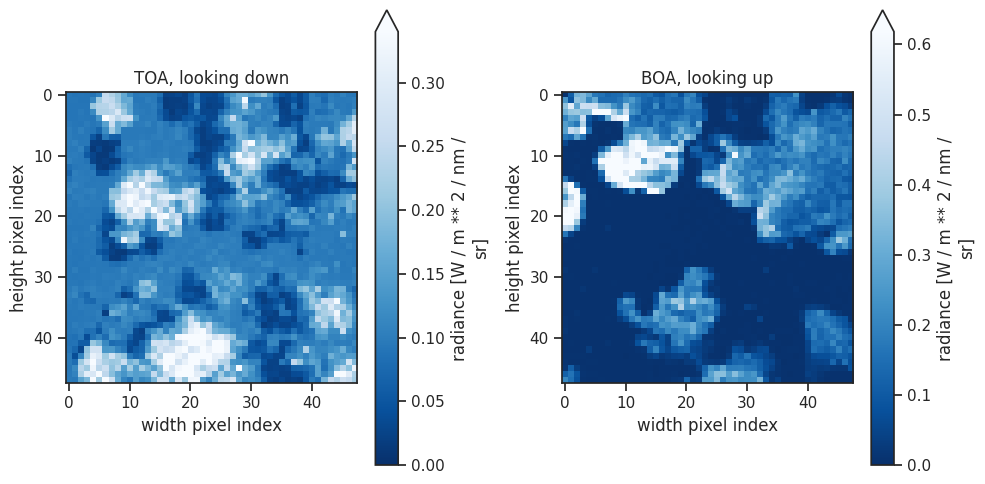

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
plot_camera(results["toa_down"].radiance, ax=ax1)
ax1.set_title("TOA, looking down")
plot_camera(results["boa_up"].radiance, ax=ax2)
ax2.set_title("BOA, looking up")
fig.tight_layout()